# Lab 9 – Morphological Operations

Ali Jafar Altaweel

2240006456

7MA2

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1. Student tasks

### Task 1 – Apply morphological operations to a new image

Select a different binary image (e.g., Balls).

Apply the morphological operations demonstrated in the lab:

- Erosion
- Dilation
- Opening
- Closing

Display the original image and the results of each operation.

### Task 2 – Experiment with structuring elements

Apply erosion and dilation using different structuring element shapes (e.g., square, cross, and ellipse).

Experiment with different kernel sizes (3×3, 5×5, and 7×7).

Compare the resulting images.

### Task 1 Solution – Erosion, dilation, opening and closing on the balls image

image: (1173, 1224)   Otsu threshold: 127.0
Original Binary    white pixels: 441981   objects:  22   holes:  38
Erosion 21x21      white pixels: 218315   objects:   1   holes:  31
Dilation 21x21     white pixels: 644454   objects:   1   holes:  75
Opening 21x21      white pixels: 408575   objects:   1   holes:  31
Closing 21x21      white pixels: 483026   objects:   4   holes:  46


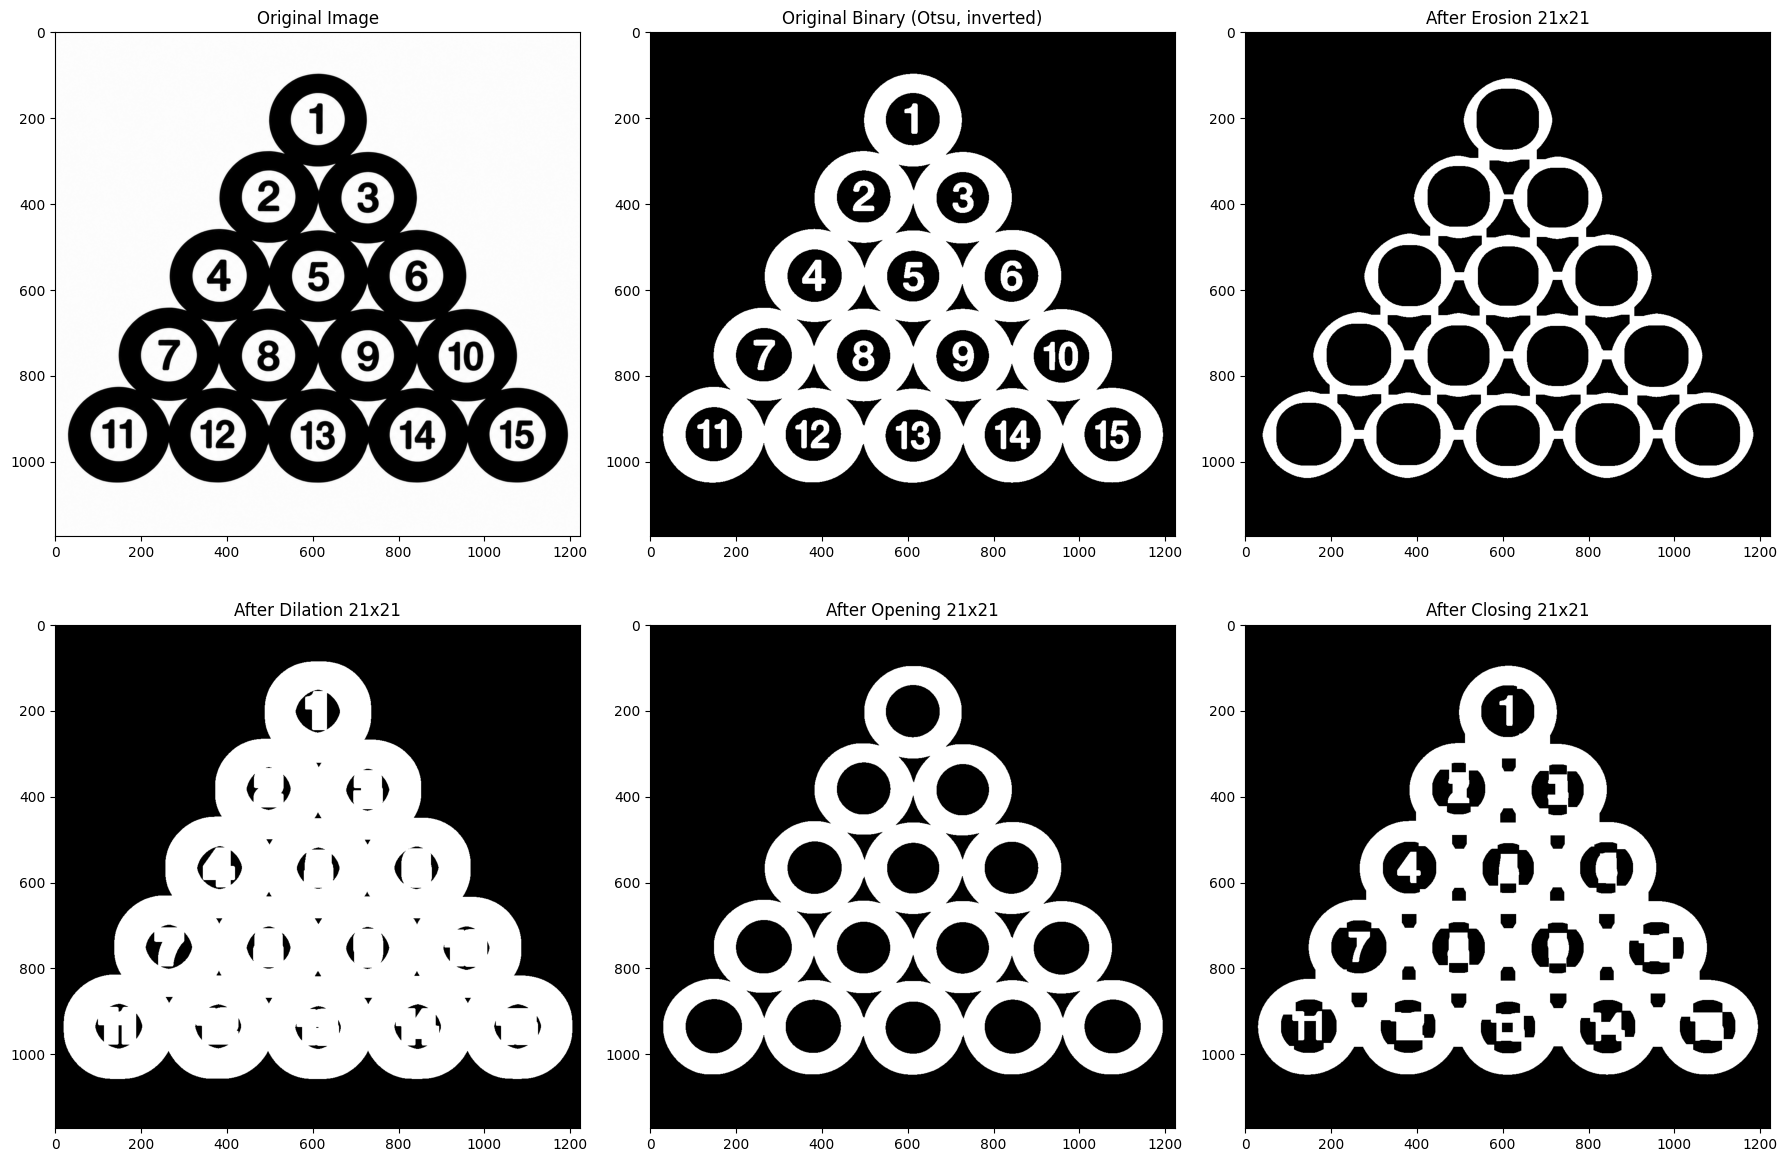


Erosion 11x11      white pixels: 320543   objects:  69   holes:  31
Erosion 21x21      white pixels: 218315   objects:   1   holes:  31
Erosion 35x35      white pixels:  71314   objects:  10   holes:  10
Dilation 11x11     white pixels: 555016   objects:  16   holes:  46
Dilation 21x21     white pixels: 644454   objects:   1   holes:  75
Dilation 35x35     white pixels: 705033   objects:   1   holes:  14
Opening 11x11      white pixels: 435243   objects:  42   holes:  31
Opening 21x21      white pixels: 408575   objects:   1   holes:  31
Opening 35x35      white pixels: 405551   objects:   1   holes:  30
Closing 11x11      white pixels: 449806   objects:  17   holes:  41
Closing 21x21      white pixels: 483026   objects:   4   holes:  46
Closing 35x35      white pixels: 597803   objects:   1   holes:  12


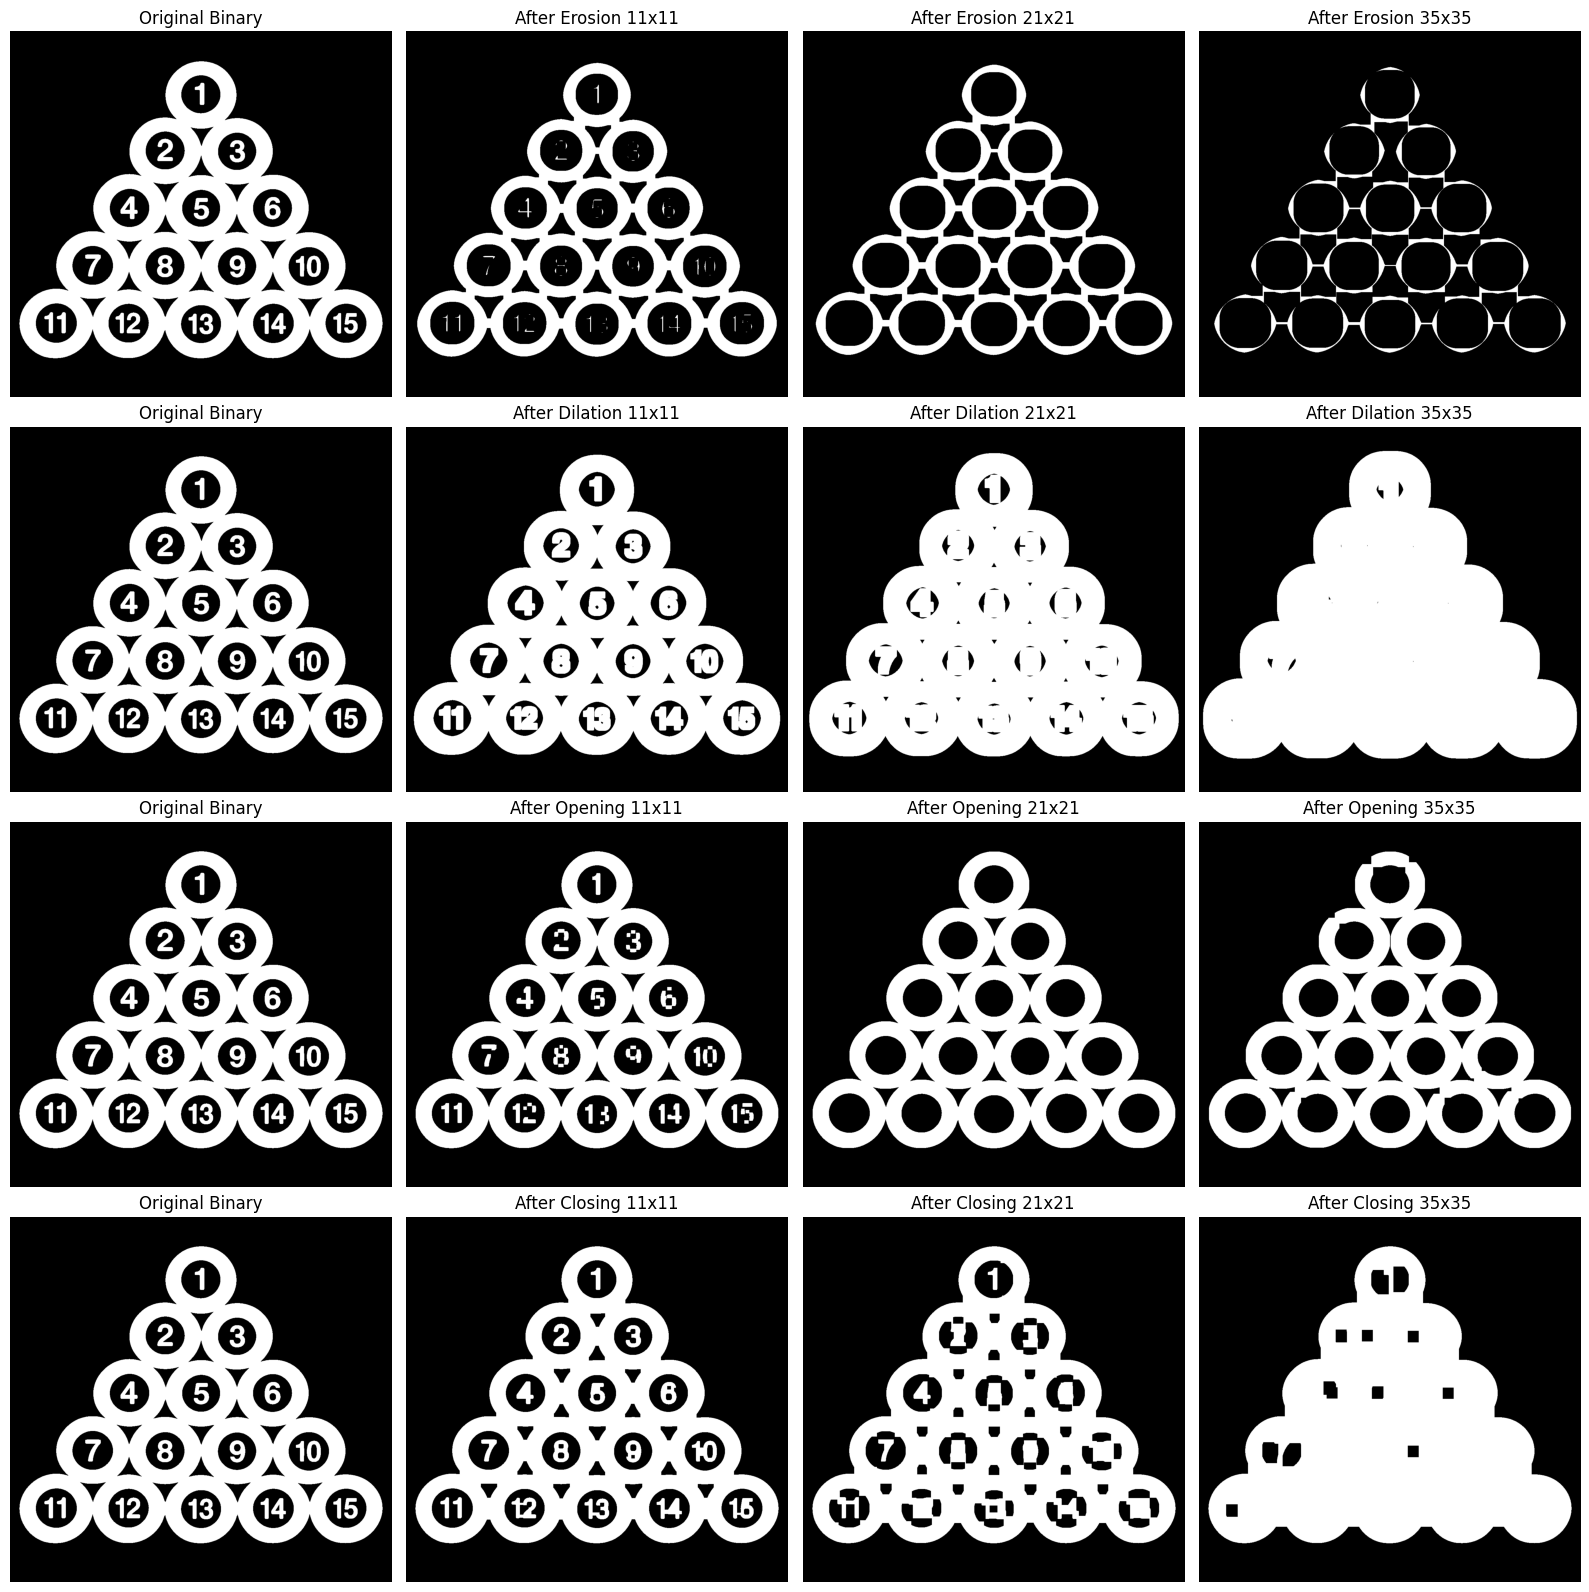

In [2]:
# the billiard balls image, used for both tasks
imgFile = './images/Balls.png'

# 1. Load the image in grayscale and cut off the thin black frame around the picture
img = cv2.imread(imgFile, 0)
img = img[25:1198, 25:1249]

# 2. Binarize the image with Otsu (same as the lab)
# the balls are black on a white background, so THRESH_BINARY_INV makes the balls the white foreground
otsu_t, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print("image:", img.shape, "  Otsu threshold:", otsu_t)

# helpers to measure each result
def count_objects(b):          # white connected regions
    return cv2.connectedComponents(b)[0] - 1

def count_holes(b):            # black regions that do not touch the image border
    n, lab = cv2.connectedComponents(255 - b)
    border = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])))
    return len(set(range(1, n)) - border)

def describe(name, b):
    print(f"{name:<18} white pixels: {(b > 0).sum():6d}   objects: {count_objects(b):3d}   holes: {count_holes(b):3d}")

# 3. Apply the four operations with a 21x21 square kernel
# the image is large (1224 x 1173) and the digit strokes are about 20 px thick, so a bigger kernel is needed to see the effect
kernel = np.ones((21, 21), np.uint8)
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)    # dilate(erode(binary))
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)   # erode(dilate(binary))

describe("Original Binary", binary)
for name, r in (("Erosion 21x21", erosion), ("Dilation 21x21", dilation), ("Opening 21x21", opening), ("Closing 21x21", closing)):
    describe(name, r)

# 4. Display the original image and the result of each operation
plt.figure(figsize=(18, 12))
plt.subplot(2, 3, 1), plt.imshow(img, 'gray'), plt.title('Original Image')
plt.subplot(2, 3, 2), plt.imshow(binary, 'gray'), plt.title('Original Binary (Otsu, inverted)')
plt.subplot(2, 3, 3), plt.imshow(erosion, 'gray'), plt.title('After Erosion 21x21')
plt.subplot(2, 3, 4), plt.imshow(dilation, 'gray'), plt.title('After Dilation 21x21')
plt.subplot(2, 3, 5), plt.imshow(opening, 'gray'), plt.title('After Opening 21x21')
plt.subplot(2, 3, 6), plt.imshow(closing, 'gray'), plt.title('After Closing 21x21')
plt.tight_layout()
plt.show()

# 5. The same four operations with 11x11, 21x21 and 35x35 kernels (rows = operation, columns = kernel size)
ops = {'Erosion': lambda b, K: cv2.erode(b, K),
       'Dilation': lambda b, K: cv2.dilate(b, K),
       'Opening': lambda b, K: cv2.morphologyEx(b, cv2.MORPH_OPEN, K),
       'Closing': lambda b, K: cv2.morphologyEx(b, cv2.MORPH_CLOSE, K)}
print()
fig, ax = plt.subplots(4, 4, figsize=(16, 16))
for i, (op, f) in enumerate(ops.items()):
    ax[i, 0].imshow(binary, 'gray'), ax[i, 0].set_title('Original Binary')
    for j, k in enumerate((11, 21, 35), start=1):
        r = f(binary, np.ones((k, k), np.uint8))
        describe(f"{op} {k}x{k}", r)
        ax[i, j].imshow(r, 'gray'), ax[i, j].set_title(f'After {op} {k}x{k}')
for a in ax.ravel(): a.axis('off')
plt.tight_layout()
plt.show()

Explanation: I used the billiard balls image. I cut off the black frame of the picture first, so it would not become an object, and binarized it with Otsu (threshold 127) and THRESH_BINARY_INV, so the black balls become white. In the binary image all 15 balls touch each other, so they form one big white object, and the 21 white digits inside the black number circles are separate objects (22 objects in total). The 38 holes are the 15 number circles, the 16 small gaps between the balls and the 7 holes inside the digits (4, 6, 8, 9, 0). I used a 21x21 kernel, because the image is large and a 3x3 kernel barely changes it. Erosion 21x21 makes the white rings thinner and removes all the digits, because their strokes are thinner than the kernel, and the balls start to separate at the points where they touch. Dilation 21x21 makes the rings thicker, fills the gaps between the balls and makes the digits grow into blobs that fill most of the number circles. Opening 21x21 removes all the digits and keeps the rings at almost the same thickness, so only one clean object is left (the rack). Closing 21x21 fills the 16 gaps between the balls, but it also joins the digits to the rings, which splits some number circles into smaller holes (46 holes). With 11x11, 21x21 and 35x35 the effect of each operation gets stronger as the kernel grows: with 35x35 erosion breaks the rings apart and dilation and closing turn the rack into an almost solid shape with only a few holes left.

### Task 2 Solution – Square, cross and ellipse structuring elements (3×3, 5×5, 7×7)

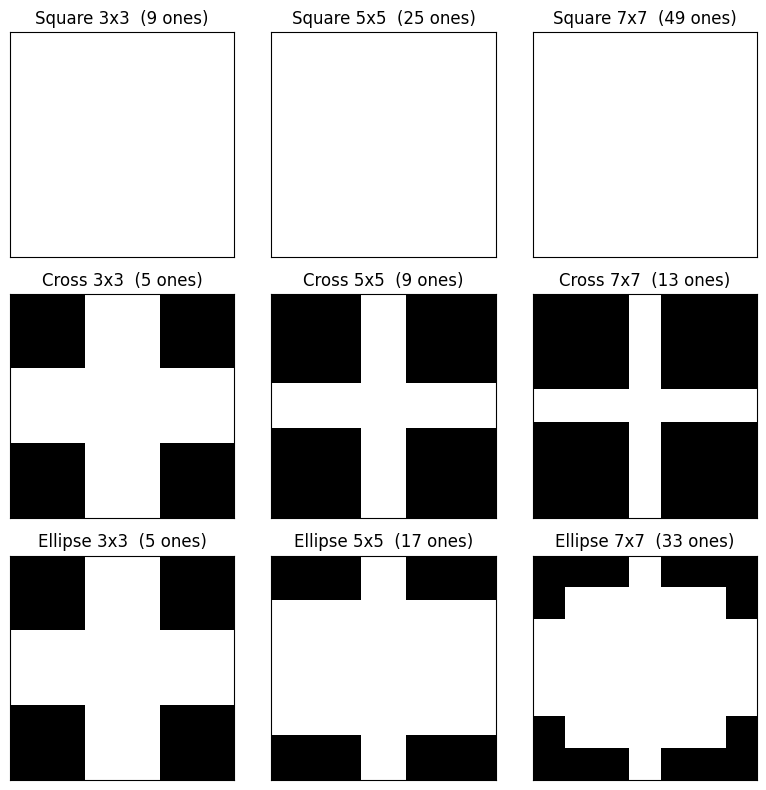

3x3 ellipse is the same as the 3x3 cross: True

SE             erosion: white px  objects  holes    dilation: white px  objects  holes
Square 3x3                417734       22     38                465969       22     41
Square 5x5                393364       22     38                489269       22     38
Square 7x7                368888       22     38                511907       22     41
Cross 3x3                 424442       22     38                459440       22     39
Cross 5x5                 406989       22     38                476540       22     38
Cross 7x7                 389618       22     38                493261       22     40
Ellipse 3x3               424442       22     38                459440       22     39
Ellipse 5x5               401853       22     38                481366       22     39
Ellipse 7x7               384130       22     38                498120       22     39


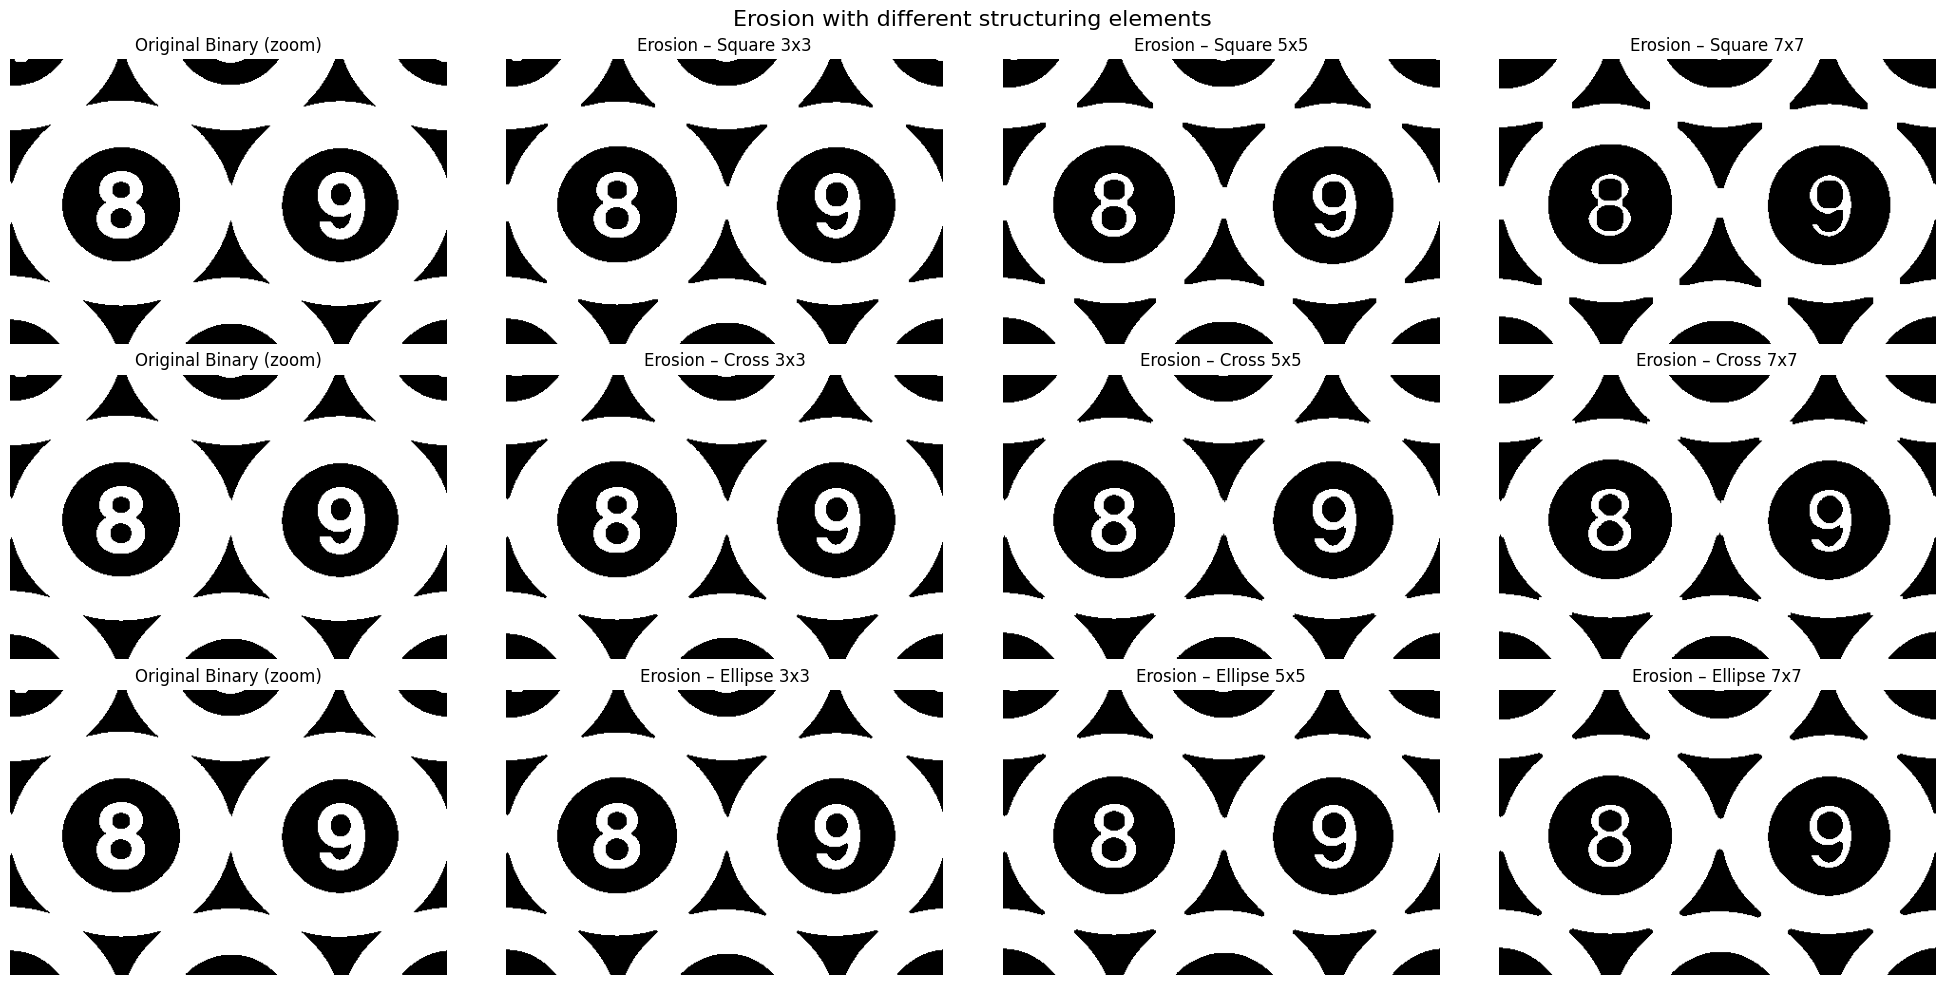

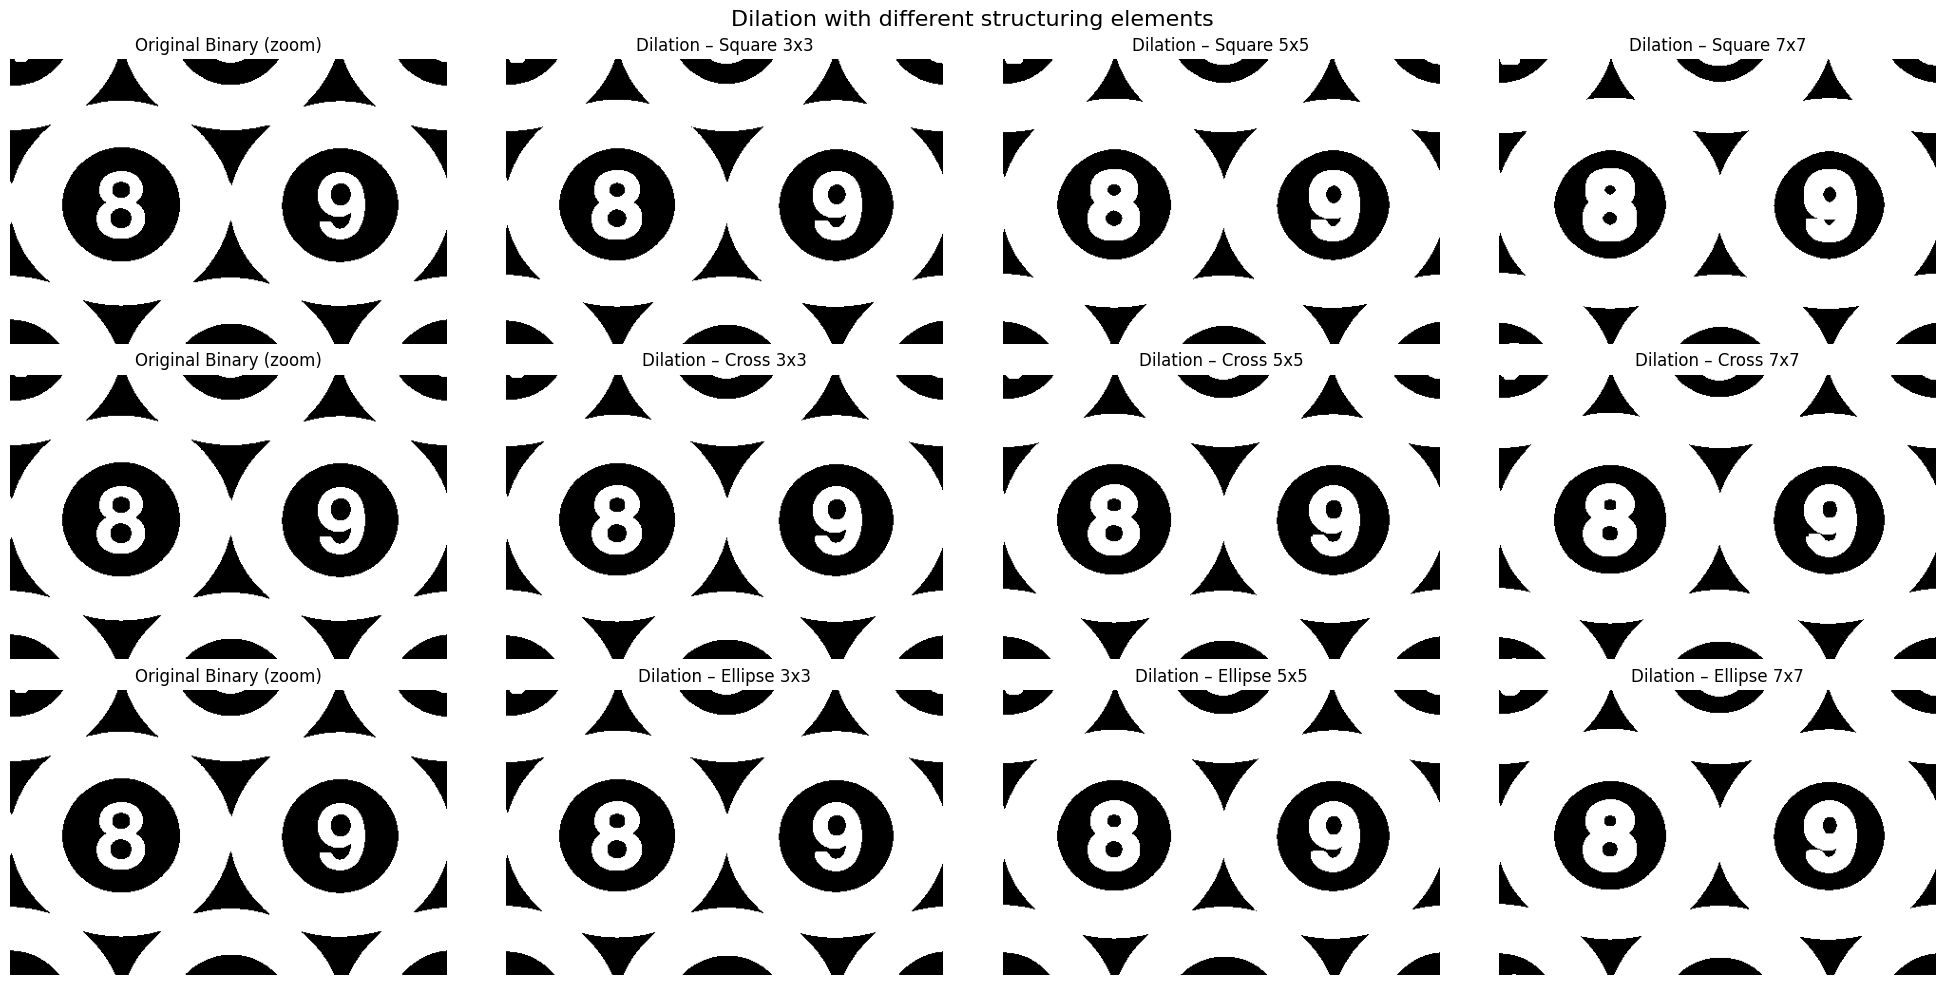

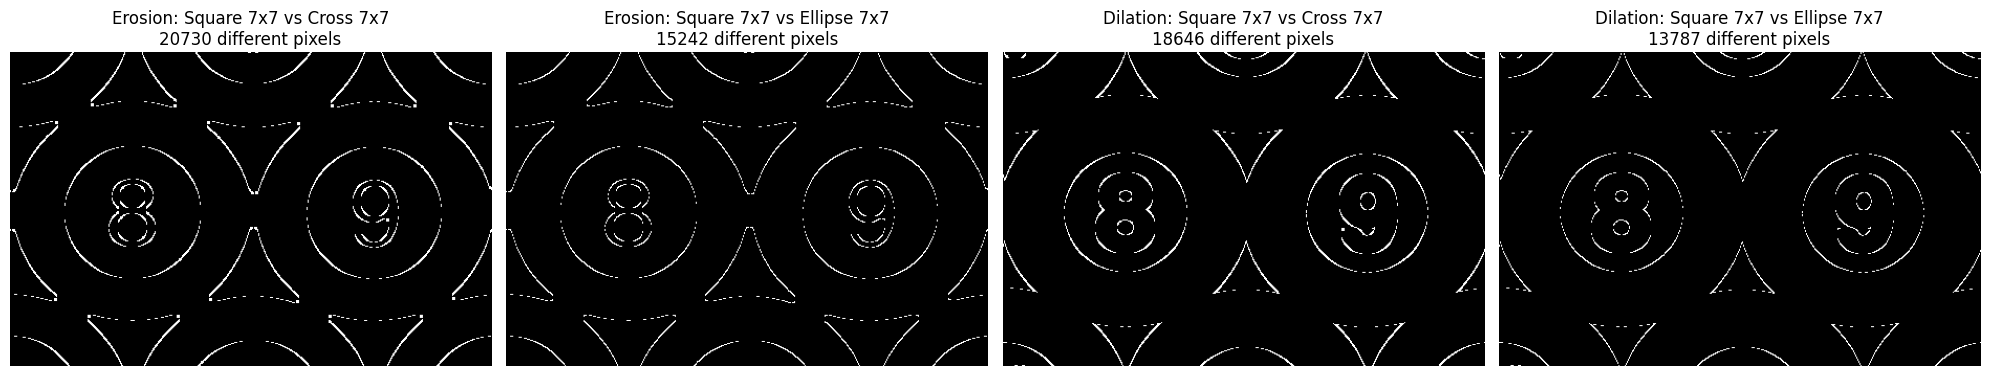

In [3]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]
ses = {(name, k): cv2.getStructuringElement(s, (k, k)) for name, s in shapes.items() for k in sizes}

# 1. The structuring elements themselves (white = 1)
fig, ax = plt.subplots(3, 3, figsize=(8, 8))
for i, name in enumerate(shapes):
    for j, k in enumerate(sizes):
        se = ses[(name, k)]
        ax[i, j].imshow(se, 'gray', vmin=0, vmax=1)
        ax[i, j].set_title(f'{name} {k}x{k}  ({se.sum()} ones)')
        ax[i, j].set_xticks([]), ax[i, j].set_yticks([])
plt.tight_layout()
plt.show()
print("3x3 ellipse is the same as the 3x3 cross:", np.array_equal(ses[('Ellipse', 3)], ses[('Cross', 3)]))

# 2. Apply erosion and dilation with every shape and size on the balls image
results = {}
print(f"\n{'SE':<14}{'erosion: white px':>18}{'objects':>9}{'holes':>7}   {'dilation: white px':>19}{'objects':>9}{'holes':>7}")
for (name, k), se in ses.items():
    e = cv2.erode(binary, se)
    d = cv2.dilate(binary, se)
    results[(name, k)] = (e, d)
    print(f"{name + f' {k}x{k}':<14}{(e > 0).sum():>18}{count_objects(e):>9}{count_holes(e):>7}   "
          f"{(d > 0).sum():>19}{count_objects(d):>9}{count_holes(d):>7}")

# 3. Compare the resulting images on a zoom of balls 8 and 9 (rows = shape, columns = size)
# the image is large, so the effect of a 3x3 to 7x7 kernel is only visible when zoomed in
crop = (slice(600, 900), slice(380, 840))
for op, idx in (('Erosion', 0), ('Dilation', 1)):
    fig, ax = plt.subplots(3, 4, figsize=(20, 10))
    for i, name in enumerate(shapes):
        ax[i, 0].imshow(binary[crop], 'gray'), ax[i, 0].set_title('Original Binary (zoom)')
        for j, k in enumerate(sizes, start=1):
            ax[i, j].imshow(results[(name, k)][idx][crop], 'gray')
            ax[i, j].set_title(f'{op} – {name} {k}x{k}')
    for a in ax.ravel(): a.axis('off')
    plt.suptitle(f'{op} with different structuring elements', fontsize=16)
    plt.tight_layout()
    plt.show()

# 4. Where the shapes differ: square 7x7 compared with cross 7x7 and ellipse 7x7 (zoom, count over the whole image)
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
pairs = [('Erosion', 0, 'Cross'), ('Erosion', 0, 'Ellipse'), ('Dilation', 1, 'Cross'), ('Dilation', 1, 'Ellipse')]
for a, (op, idx, name) in zip(ax, pairs):
    diff = cv2.absdiff(results[('Square', 7)][idx], results[(name, 7)][idx])
    a.imshow(diff[crop], 'gray'), a.set_title(f'{op}: Square 7x7 vs {name} 7x7\n{(diff > 0).sum()} different pixels')
    a.axis('off')
plt.tight_layout()
plt.show()

Explanation: The square has all 49 ones at 7x7, the ellipse 33 and the cross only 13, so for the same size the square has the strongest effect and the cross the weakest: erosion 7x7 keeps 368,888 white pixels with the square, 384,130 with the ellipse and 389,618 with the cross, and dilation 7x7 gives 511,907, 498,120 and 493,261. For every shape a bigger kernel gives a stronger effect: the digits and the rings get thinner with erosion and thicker with dilation. The number of objects (22) and holes (38) did not change with erosion for any shape, because the image is clean and large, so a 3x3 to 7x7 kernel only moves the outlines by a few pixels and does not remove or join anything. The zoom on balls 8 and 9 shows the difference in shape: the square makes the corners of the gaps and the digits blocky, the ellipse keeps them round, and the cross changes the outlines the least, only in the horizontal and vertical directions, because it has no diagonal. The difference images show that the shapes only differ on the edges (13,787 to 20,730 pixels). In OpenCV the 3x3 ellipse is exactly the same as the 3x3 cross, so those two rows give the same numbers.